In [7]:
import numpy as np
import pandas as pd
import keras
from keras import layers


In [8]:
x_train = pd.read_csv('../data/processed/x_train_scaled.csv').to_numpy()
x_val   = pd.read_csv('../data/processed/x_val_scaled.csv').to_numpy()
y_train = pd.read_csv('../data/processed/y_train.csv').to_numpy()
y_val   = pd.read_csv('../data/processed/y_val.csv').to_numpy()
x_test  = pd.read_csv('../data/processed/x_test_scaled.csv').to_numpy()
y_test  = pd.read_csv('../data/processed/y_test.csv').to_numpy()

In [9]:
n_features = x_train.shape[1]            
x_train = x_train.reshape(-1, 1, n_features)
x_val   = x_val.reshape(-1, 1, n_features)
x_test  = x_test.reshape(-1, 1, n_features)

print(x_train.shape, x_val.shape, x_test.shape) 

(16138, 1, 17) (4493, 1, 17) (13096, 1, 17)


In [10]:

input = layers.Input(shape=(1, n_features))
x = layers.LSTM(64, return_sequences=True)(input)
x = layers.LSTM(32)(x)
x = layers.Dense(16, activation='relu')(x)
output = layers.Dense(1)(x)
model = keras.Model(inputs=input, outputs=output)


model.compile(optimizer='adam', loss='mse', metrics=['mae'])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath='../models/gru_model.keras',
        save_best_only=True,
        monitor='val_loss',
    )
]

In [11]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 9389.3145 - mae: 76.5734 - val_loss: 5863.1797 - val_mae: 54.5309
Epoch 2/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2162.3657 - mae: 32.8499 - val_loss: 2898.5459 - val_mae: 37.6753
Epoch 3/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1578.1005 - mae: 28.2497 - val_loss: 2679.2014 - val_mae: 36.8153
Epoch 4/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1518.2039 - mae: 27.6335 - val_loss: 2554.6001 - val_mae: 36.2254
Epoch 5/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1499.7749 - mae: 27.4059 - val_loss: 2575.7117 - val_mae: 36.3734
Epoch 6/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1493.1555 - mae: 27.2774 - val_loss: 2568.8708 - val_mae: 36.2723
Epoch 7/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1485.9946 - mae: 27.1275 - val_loss: 2512.1077 - val_mae: 36.0791
Epoch 8/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1480.8190 - mae: 27.0994 - val_loss: 2565.3176 - v

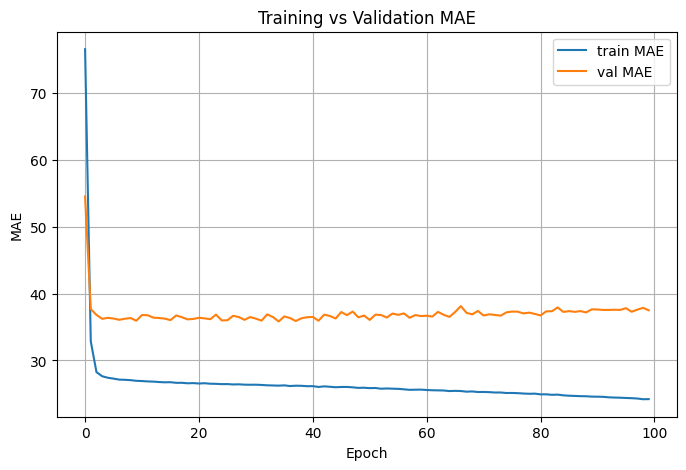

In [12]:
# elbow method
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history["mae"], label="train MAE")
plt.plot(history.history["val_mae"], label="val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

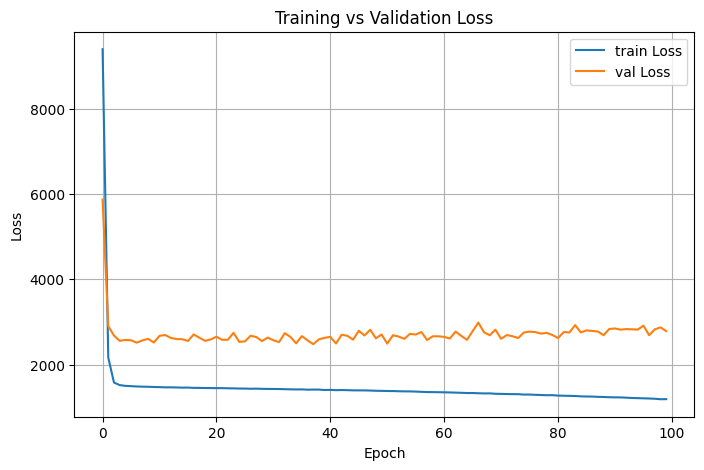

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="train Loss")
plt.plot(history.history["val_loss"], label="val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
model = keras.models.load_model("../models/gru_model.keras")

print(f"Model evaluation on test set: Loss = {model.evaluate(x_test , y_test)[0]}, MAE = {model.evaluate(x_test , y_test)[1]}")

410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6707.9634 - mae: 69.5785
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6707.9634 - mae: 69.5785
Model evaluation on test set: Loss = 6707.96337890625, MAE = 69.57850646972656
